# Hälsostudie del 2
I del 2 är koden fårn del 1 flytttad till en klass, Healthanalyzer, i modulen src/health_analyzer.py. 

In [1]:
import pandas as pd
from src.health_analyzer import HealthAnalyzer

df = pd.read_csv("data/health_study_dataset (1).csv")
analys = HealthAnalyzer(df)

analys.describe(["age", "weight", "height", "systolic_bp", "cholesterol"])

,age,weight,height,systolic_bp,cholesterol
mean,49.43,73.41,171.85,149.18,4.93
median,50.00,73.20,171.35,149.40,4.97
min,18.00,33.70,144.40,106.80,2.50
max,90.00,114.40,200.40,185.90,7.88


klassens HealthAnalyzer ger samma besrivande statistik som i del 1, men nu med ett enda metodanrop: analys.desribe(...) Deltagarna är i genomsnitt cirka 49år, väger 73kg, och har ett systoliskt blodtryck på 149mmHg. Medel och median ligger nära varandra för alla variabler, vilket tyder på nästa symmetrisk fördeling

Andel med sjukdomen: 5.9 %
95 % KI för blodtryck: 148.3 till 150.1 mmHg


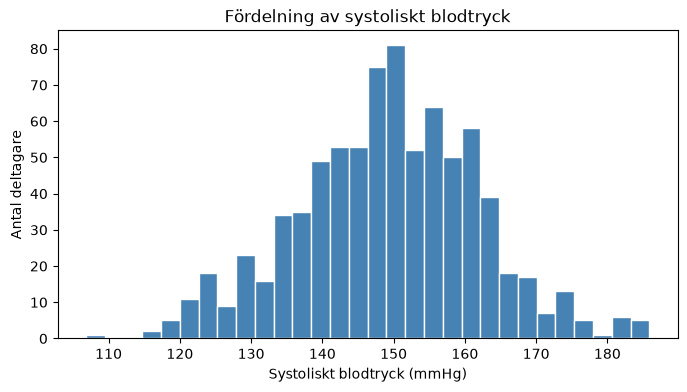

In [2]:
print("Andel med sjukdomen:", round(analys.disease_share() * 100, 1), "%")

nedre, ovre = analys.confidence_interval("systolic_bp")
print("95 % KI för blodtryck:", round(nedre, 1), "till", round(ovre, 1), "mmHg")

analys.plot_histogram("systolic_bp", "Fördelning av systoliskt blodtryck", "Systoliskt blodtryck (mmHg)")

metoderna i klassen ger samma resultat som i del 1: 5,9% av deltagarna har sjukdomen, och 95% konfidensintervallet för medelvärdet av blodtrycket är 148,3 till 150,1 mmHg.

## Linjär regression: blodtryck och ålder
Undersökte om det systoliska blodtrycket ökar med åldern. Anpassade en linjär regression, blodtryck = a+b*ålder, med minsta kvadratmetoden. Koefficienterna räknas ut med matriser i numpy (np.linalg.lstsq).

Intercept (a): 122.68
Lutning (b): 0.54 mmHg per år


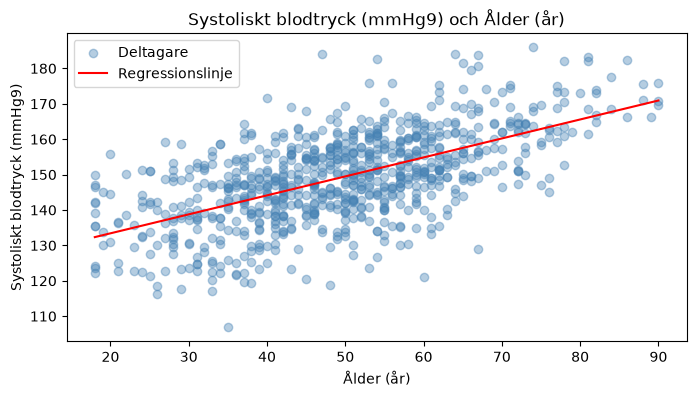

In [3]:
a, b = analys.linear_regression("age", "systolic_bp")

print("Intercept (a):", round(a, 2))
print("Lutning (b):", round(b, 2), "mmHg per år")

analys.plot_regression("age", "systolic_bp", "Ålder (år)", "Systoliskt blodtryck (mmHg9)")

### Uppfattning
regressionslinjen är blodtryck a+b*ålder. Lutningen B betyder att det systoliska blodtrycker ökar med cirka b mmHg för varje år äldre en deltagare blir. Över 40 år motsvarar cirka (40 x b) mmHg.

I spridningsdiagrammet ligger punkterna ändå utspridda längs linjen. Åldern förklarar altså en del av blodtrycket, men inte allt. 

Metodval - linjär regression med minsta kvadratmedtoden passar när man vill beskriva ett linjärt samband mellan två numeriska variabler. Koefficienterna räknas ut genom att lösa ett ekvationssystem med matriser i numpy.

In [4]:
print("Ökning över 40 år:", round(40 * b, 1), "mmHg")

Ökning över 40 år: 21.4 mmHg
